# 06. Model Evaluation & Comparison
## Objectives:
- Load the preprocessor and trained models (`xgboost_delay_model.joblib`, `random_forest_delay_model.joblib`, etc.).
- Generate classification reports (Precision, Recall, F1-Score) for each model.
- Plot confusion matrices to visualize true vs. predicted delay categories (0, 1, 2).
- Inspect feature importances to see which factors drive supply chain delays.

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/home/patel-krish/anaconda3/BrainyBeam/SuplyChainDelay/data/syndelay_v1.csv')

In [3]:
num_cols = ['sales', 'profit_per_order', 'order_item_quantity', 'order_item_discount_rate', 
            'product_price', 'sales_per_customer', 'latitude', 'longitude']
cat_cols = ['shipping_mode', 'market', 'customer_segment', 'department_name']

In [4]:
X = df[num_cols + cat_cols]
y = df['label']

In [5]:
preprocessor = joblib.load('../models/preprocessor.joblib')
xgb_model = joblib.load('../models/xgboost_delay_model.joblib')

In [6]:
X_proc = preprocessor.transform(X)
y_pred = xgb_model.predict(X_proc)

In [17]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score

In [18]:
print("--- XGBoost Classification Report ---")
print(classification_report(y, y_pred, target_names=['On-Time (0)', 'Moderate Delay (1)', 'Severe Delay (2)']))

--- XGBoost Classification Report ---
                    precision    recall  f1-score   support

       On-Time (0)       0.47      0.43      0.45     36724
Moderate Delay (1)       0.59      0.09      0.16     29055
  Severe Delay (2)       0.65      0.85      0.74     89709

          accuracy                           0.61    155488
         macro avg       0.57      0.46      0.45    155488
      weighted avg       0.60      0.61      0.56    155488



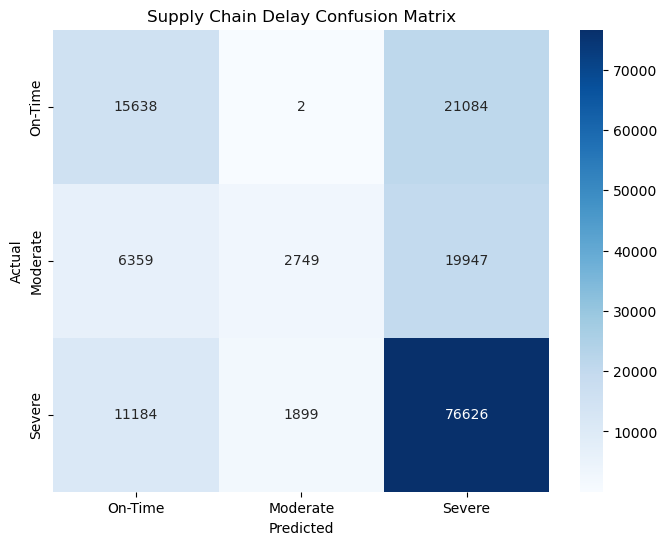

In [19]:
# Plot Confusion Matrix
cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['On-Time', 'Moderate', 'Severe'], yticklabels=['On-Time', 'Moderate', 'Severe'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Supply Chain Delay Confusion Matrix')
plt.show()

--- XGBoost Classification Report ---
                    precision    recall  f1-score   support

       On-Time (0)       0.47      0.43      0.45     36724
Moderate Delay (1)       0.59      0.09      0.16     29055
  Severe Delay (2)       0.65      0.85      0.74     89709

          accuracy                           0.61    155488
         macro avg       0.57      0.46      0.45    155488
      weighted avg       0.60      0.61      0.56    155488



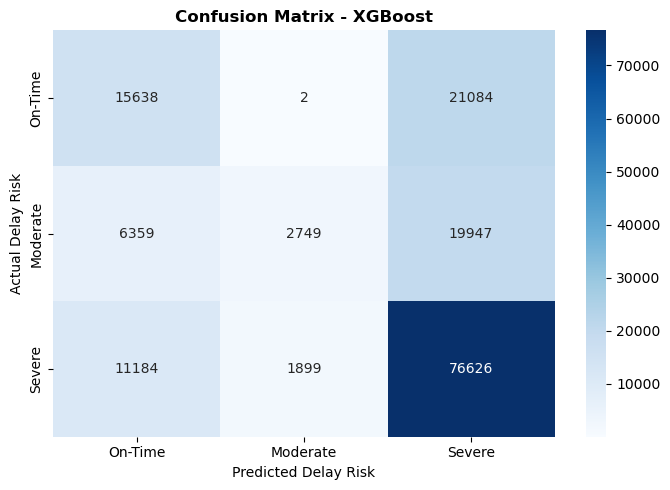

In [20]:
# 2. Load and Evaluate XGBoost
xgb_model = joblib.load('../models/xgboost_delay_model.joblib')
y_pred_xgb = xgb_model.predict(X_proc)

print("--- XGBoost Classification Report ---")
print(classification_report(y, y_pred_xgb, target_names=['On-Time (0)', 'Moderate Delay (1)', 'Severe Delay (2)']))

# Confusion Matrix for XGBoost
cm_xgb = confusion_matrix(y, y_pred_xgb)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['On-Time', 'Moderate', 'Severe'], 
            yticklabels=['On-Time', 'Moderate', 'Severe'])
plt.title('Confusion Matrix - XGBoost', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Delay Risk')
plt.ylabel('Actual Delay Risk')
plt.tight_layout()
plt.show()

## Evaluating Random Forest Model Performance

--- Random Forest Classification Report ---
                    precision    recall  f1-score   support

       On-Time (0)       0.59      0.26      0.36     36724
Moderate Delay (1)       0.77      0.10      0.17     29055
  Severe Delay (2)       0.63      0.95      0.76     89709

          accuracy                           0.63    155488
         macro avg       0.66      0.44      0.43    155488
      weighted avg       0.65      0.63      0.55    155488



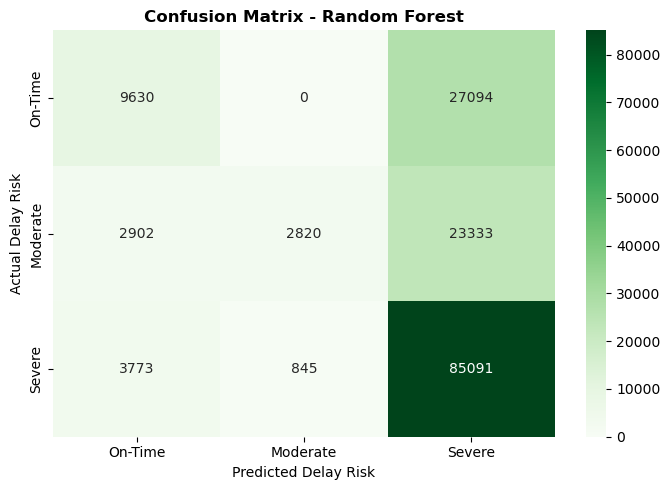

In [21]:
# 3. Load and Evaluate Random Forest
rf_model = joblib.load('../models/random_forest_delay_model.joblib')
y_pred_rf = rf_model.predict(X_proc)

print("--- Random Forest Classification Report ---")
print(classification_report(y, y_pred_rf, target_names=['On-Time (0)', 'Moderate Delay (1)', 'Severe Delay (2)']))

# Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['On-Time', 'Moderate', 'Severe'], 
            yticklabels=['On-Time', 'Moderate', 'Severe'])
plt.title('Confusion Matrix - Random Forest', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Delay Risk')
plt.ylabel('Actual Delay Risk')
plt.tight_layout()
plt.show()

## Evaluating LightGBM Model Performance

In [22]:
#  Load and Evaluate LightGBM

/home/patel-krish/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


--- LightGBM Classification Report ---
                    precision    recall  f1-score   support

       On-Time (0)       0.48      0.47      0.47     36724
Moderate Delay (1)       0.59      0.09      0.16     29055
  Severe Delay (2)       0.66      0.85      0.74     89709

          accuracy                           0.62    155488
         macro avg       0.58      0.47      0.46    155488
      weighted avg       0.61      0.62      0.57    155488



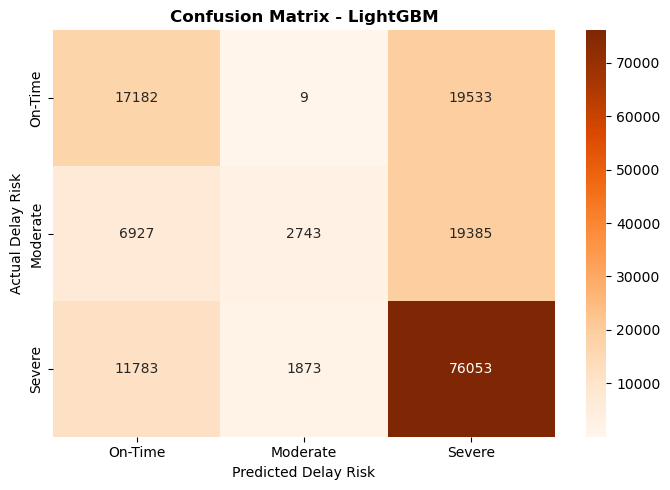

In [23]:
lgb_model = joblib.load('../models/lightgbm_delay_model.joblib')
y_pred_lgb = lgb_model.predict(X_proc)

print("--- LightGBM Classification Report ---")
print(classification_report(y, y_pred_lgb, target_names=['On-Time (0)', 'Moderate Delay (1)', 'Severe Delay (2)']))

# Confusion Matrix for LightGBM
cm_lgb = confusion_matrix(y, y_pred_lgb)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['On-Time', 'Moderate', 'Severe'], 
            yticklabels=['On-Time', 'Moderate', 'Severe'])
plt.title('Confusion Matrix - LightGBM', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Delay Risk')
plt.ylabel('Actual Delay Risk')
plt.tight_layout()
plt.show()

#  Updated Multi-Model Accuracy Comparison

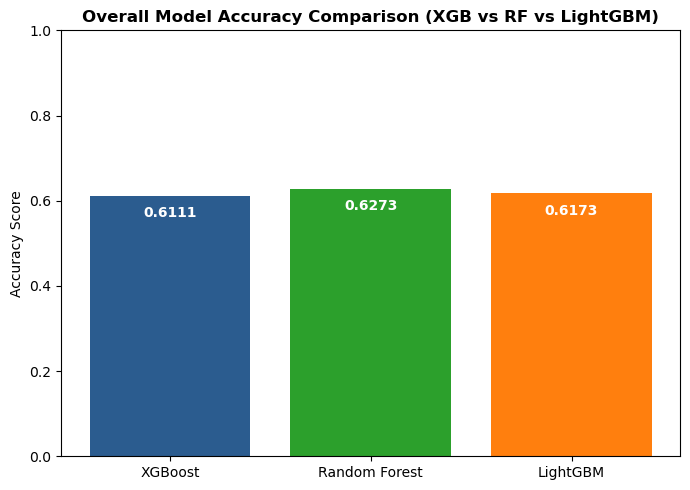

In [25]:
# 5. Updated Multi-Model Accuracy Comparison
models_perf = {
    'XGBoost': accuracy_score(y, y_pred_xgb),
    'Random Forest': accuracy_score(y, y_pred_rf),
    'LightGBM': accuracy_score(y, y_pred_lgb)
}

plt.figure(figsize=(7, 5))
bars = plt.bar(models_perf.keys(), models_perf.values(), color=['#2b5c8f', '#2ca02c', '#ff7f0e'])
plt.ylim(0, 1.0)
plt.title('Overall Model Accuracy Comparison (XGB vs RF vs LightGBM)', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy Score')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval - 0.05, f"{yval:.4f}", ha='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()